In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import statsmodels.api as sm

from src.data import *
from src.models import *
from src.features import log_returns, realised_volatility
from src.backtest import walk_forward
from src.metrics import compare_models, dm_table

/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


### ==== Validation =====

In [2]:
spot = load_brent_spot(start="1987-01-01")
data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()


val_args = dict(horizon=1, start_date="2024-01-01", end_date="2025-12-31", target_end_date="2025-12-31")


val_results = {
    "Random Walk": walk_forward(data, forecast_funct=random_walk_forecast, **val_args),
    "Historical Mean": walk_forward(data, forecast_funct=historical_mean_forecast, lookback=3000, **val_args),
    "AR": walk_forward(data, forecast_funct=ar1_forecast, lookback=3000, **val_args),
    "Direct Forecast": walk_forward(data, forecast_funct=direct_forecast, lookback=3000, **val_args),
    "Direct Lag_1 Lag_60": walk_forward(data, forecast_funct=direct_lags_forecast, short=1, long=60, lookback=3000, **val_args),
    "Direct Lag_5 Lag_60": walk_forward(data, forecast_funct=direct_lags_forecast, short=5, long=60, lookback=3000, **val_args)
}

compare_models(val_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,num_trades
model,,,,,,,,,,,,,,
Random Walk,1.017925,1.337748,1.373841,0.005929,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.0
Historical Mean,1.018121,1.337821,1.373962,0.501976,0.000000,0.000000,0.000000,0.501976,1.000000,0.668421,-0.012542,-0.383374,-0.034918,1.0
AR,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Forecast,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Lag_1 Lag_60,1.017655,1.338184,1.373511,0.488142,0.478723,0.361446,0.411899,0.493711,0.618110,0.548951,0.029255,0.991013,-0.013107,5.0
Direct Lag_5 Lag_60,1.016544,1.336837,1.371741,0.523715,0.528497,0.409639,0.461538,0.520767,0.641732,0.574956,-0.010090,-0.306901,-0.053881,7.0


#### Mean Revert

In [3]:
# PRICES = ["brent_spot", "wti", "usd", "sp500"]   # prices -> log returns
# INDICES = ["vix", "ovx", "epu", "gpr"]           # fear/uncertainty indices -> log levels

df_mr = load_dataset()
df_mr = df_mr[["brent_spot", "wti"]]
df_mr = df_mr.rename(columns={"wti": "wti_spot"})
df_mr["log_return"] = np.log(df_mr["brent_spot"]).diff()
df_mr = df_mr.dropna()

df_mr.tail()

,brent_spot,wti_spot,log_return
DATE,,,
2026-10-21,117.37,103.95,0.018488
2026-10-22,125.39,104.27,0.066098
2026-10-23,128.30,109.72,0.022942
2026-10-26,128.12,105.25,-0.001404
2026-10-27,123.10,103.37,-0.039970


In [4]:
val_forecast = walk_forward(df_mr, forecast_funct=spread_mr_forecast, lookback=3000, **val_args)
val_forecast.tail()

,origin_date,target_date,origin_price,forecast,actual
501,2025-12-22,2025-12-23,62.22,62.162044,63.70
502,2025-12-23,2025-12-24,63.70,63.534057,63.70
503,2025-12-24,2025-12-29,63.70,63.552391,63.10
504,2025-12-29,2025-12-30,63.10,62.924637,62.30
505,2025-12-30,2025-12-31,62.30,62.193352,61.35


In [5]:
val_results["Mean Revert"] = val_forecast

compare_models(val_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,num_trades
model,,,,,,,,,,,,,,
Random Walk,1.017925,1.337748,1.373841,0.005929,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.0
Historical Mean,1.018121,1.337821,1.373962,0.501976,0.000000,0.000000,0.000000,0.501976,1.000000,0.668421,-0.012542,-0.383374,-0.034918,1.0
AR,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Forecast,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Lag_1 Lag_60,1.017655,1.338184,1.373511,0.488142,0.478723,0.361446,0.411899,0.493711,0.618110,0.548951,0.029255,0.991013,-0.013107,5.0
Direct Lag_5 Lag_60,1.016544,1.336837,1.371741,0.523715,0.528497,0.409639,0.461538,0.520767,0.641732,0.574956,-0.010090,-0.306901,-0.053881,7.0
Mean Revert,1.012017,1.327569,1.366409,0.503953,0.500000,0.710843,0.587065,0.513158,0.307087,0.384236,-0.021133,-0.667783,-0.043405,9.0


#### XGBoost

In [6]:
val_forecast = walk_forward(data, forecast_funct=xgb_direct_forecast, lookback=3000, **val_args)
val_forecast.tail()

,origin_date,target_date,origin_price,forecast,actual
501,2025-12-22,2025-12-23,62.22,62.229814,63.70
502,2025-12-23,2025-12-24,63.70,63.713357,63.70
503,2025-12-24,2025-12-29,63.70,63.701865,63.10
504,2025-12-29,2025-12-30,63.10,63.098841,62.30
505,2025-12-30,2025-12-31,62.30,62.303379,61.35


In [7]:
val_results["XGBoost"] = val_forecast

compare_models(val_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,num_trades
model,,,,,,,,,,,,,,
Random Walk,1.017925,1.337748,1.373841,0.005929,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.0
Historical Mean,1.018121,1.337821,1.373962,0.501976,0.000000,0.000000,0.000000,0.501976,1.000000,0.668421,-0.012542,-0.383374,-0.034918,1.0
AR,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Forecast,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Lag_1 Lag_60,1.017655,1.338184,1.373511,0.488142,0.478723,0.361446,0.411899,0.493711,0.618110,0.548951,0.029255,0.991013,-0.013107,5.0
Direct Lag_5 Lag_60,1.016544,1.336837,1.371741,0.523715,0.528497,0.409639,0.461538,0.520767,0.641732,0.574956,-0.010090,-0.306901,-0.053881,7.0
Mean Revert,1.012017,1.327569,1.366409,0.503953,0.500000,0.710843,0.587065,0.513158,0.307087,0.384236,-0.021133,-0.667783,-0.043405,9.0
XGBoost,1.022330,1.343937,1.380448,0.486166,0.488223,0.915663,0.636872,0.461538,0.070866,0.122867,0.012449,0.380871,-0.020497,1.0


#### Direct Ridge Forecast

In [8]:
df_rr = load_dataset()
  
df_rr = df_rr[["brent_spot", "wti", "usd", "sp500", "vix", "ovx"]]
df_rr = df_rr.rename(columns={"wti": "wti_spot"})
df_rr = df_rr.dropna()

for col in ["usd", "sp500", "vix", "ovx"]:
    df_rr[col] = np.log(df_rr[col])

df_rr.tail()

,brent_spot,wti_spot,usd,sp500,vix,ovx
DATE,,,,,,
2026-10-21,117.37,103.95,4.798615,8.956373,2.814210,3.975561
2026-10-22,125.39,104.27,4.798704,8.944215,2.946017,4.018902
2026-10-23,128.30,109.72,4.798433,8.939014,2.967847,4.094678
2026-10-26,128.12,105.25,4.798433,8.945954,2.911807,4.072610
2026-10-27,123.10,103.37,4.798433,8.951906,2.863343,4.015301


In [9]:
val_forecast = walk_forward(df_rr, forecast_funct=direct_ridge_forecast, lookback=3000, **val_args)
val_forecast.tail()

,origin_date,target_date,origin_price,forecast,actual
501,2025-12-22,2025-12-23,62.22,62.281743,63.70
502,2025-12-23,2025-12-24,63.70,63.659620,63.70
503,2025-12-24,2025-12-29,63.70,63.680214,63.10
504,2025-12-29,2025-12-30,63.10,63.035693,62.30
505,2025-12-30,2025-12-31,62.30,62.303057,61.35


In [10]:
val_results["Direct Ridge"] = val_forecast

compare_models(val_results,  horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,num_trades
model,,,,,,,,,,,,,,
Random Walk,1.017925,1.337748,1.373841,0.005929,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.0
Historical Mean,1.018121,1.337821,1.373962,0.501976,0.000000,0.000000,0.000000,0.501976,1.000000,0.668421,-0.012542,-0.383374,-0.034918,1.0
AR,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Forecast,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Lag_1 Lag_60,1.017655,1.338184,1.373511,0.488142,0.478723,0.361446,0.411899,0.493711,0.618110,0.548951,0.029255,0.991013,-0.013107,5.0
Direct Lag_5 Lag_60,1.016544,1.336837,1.371741,0.523715,0.528497,0.409639,0.461538,0.520767,0.641732,0.574956,-0.010090,-0.306901,-0.053881,7.0
Mean Revert,1.012017,1.327569,1.366409,0.503953,0.500000,0.710843,0.587065,0.513158,0.307087,0.384236,-0.021133,-0.667783,-0.043405,9.0
XGBoost,1.022330,1.343937,1.380448,0.486166,0.488223,0.915663,0.636872,0.461538,0.070866,0.122867,0.012449,0.380871,-0.020497,1.0
Direct Ridge,1.005928,1.330370,1.356872,0.563241,0.545171,0.702811,0.614035,0.594595,0.433071,0.501139,-0.000153,-0.004605,-0.043405,7.0


#### Combination Forecast

In [11]:
weights = [0.1, 0.35, 0.2, 0.35]
val_forecast = walk_forward(data, forecast_funct=combination_forecast, weights=weights, **val_args)
val_forecast.tail()

,origin_date,target_date,origin_price,forecast,actual
501,2025-12-22,2025-12-23,62.22,62.203496,63.70
502,2025-12-23,2025-12-24,63.70,63.677639,63.70
503,2025-12-24,2025-12-29,63.70,63.692384,63.10
504,2025-12-29,2025-12-30,63.10,63.098424,62.30
505,2025-12-30,2025-12-31,62.30,62.301436,61.35


In [12]:
val_results["Combination"] = val_forecast

compare_models(val_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,num_trades
model,,,,,,,,,,,,,,
Random Walk,1.017925,1.337748,1.373841,0.005929,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.0
Historical Mean,1.018121,1.337821,1.373962,0.501976,0.000000,0.000000,0.000000,0.501976,1.000000,0.668421,-0.012542,-0.383374,-0.034918,1.0
AR,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Forecast,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Lag_1 Lag_60,1.017655,1.338184,1.373511,0.488142,0.478723,0.361446,0.411899,0.493711,0.618110,0.548951,0.029255,0.991013,-0.013107,5.0
Direct Lag_5 Lag_60,1.016544,1.336837,1.371741,0.523715,0.528497,0.409639,0.461538,0.520767,0.641732,0.574956,-0.010090,-0.306901,-0.053881,7.0
Mean Revert,1.012017,1.327569,1.366409,0.503953,0.500000,0.710843,0.587065,0.513158,0.307087,0.384236,-0.021133,-0.667783,-0.043405,9.0
XGBoost,1.022330,1.343937,1.380448,0.486166,0.488223,0.915663,0.636872,0.461538,0.070866,0.122867,0.012449,0.380871,-0.020497,1.0
Direct Ridge,1.005928,1.330370,1.356872,0.563241,0.545171,0.702811,0.614035,0.594595,0.433071,0.501139,-0.000153,-0.004605,-0.043405,7.0


### ==== Diebold-Mariano test ====

In [13]:
for loss in ["ae", "se"]:
    print(f"\nDM test vs Random Walk, loss = {loss}")
    print(dm_table(val_results, benchmark="Random Walk", horizon=60, loss=loss).round(4))


DM test vs Random Walk, loss = ae
                     DM_stat  p_value      n
Historical Mean       0.3666   0.7141  506.0
AR                    1.7198   0.0861  506.0
Direct Forecast       1.7198   0.0861  506.0
Direct Lag_1 Lag_60   0.5569   0.5778  506.0
Direct Lag_5 Lag_60  -0.7061   0.4805  506.0
Mean Revert              NaN      NaN  506.0
XGBoost               2.0380   0.0421  506.0
Direct Ridge         -3.1998   0.0015  506.0
Combination           1.6558   0.0984  506.0

DM test vs Random Walk, loss = se
                     DM_stat  p_value      n
Historical Mean       0.3666   0.7141  506.0
AR                    1.7198   0.0861  506.0
Direct Forecast       1.7198   0.0861  506.0
Direct Lag_1 Lag_60   0.5569   0.5778  506.0
Direct Lag_5 Lag_60  -0.7061   0.4805  506.0
Mean Revert              NaN      NaN  506.0
XGBoost               2.0380   0.0421  506.0
Direct Ridge         -3.1998   0.0015  506.0
Combination           1.6558   0.0984  506.0


/Users/Home/Documents/Sample-Taxed/notebooks/../src/metrics.py:106: RuntimeWarning: invalid value encountered in sqrt
  dm_stat = d.mean() / np.sqrt(variance / n) # like a t-stat: average gap / its standard error
/Users/Home/Documents/Sample-Taxed/notebooks/../src/metrics.py:106: RuntimeWarning: invalid value encountered in sqrt
  dm_stat = d.mean() / np.sqrt(variance / n) # like a t-stat: average gap / its standard error


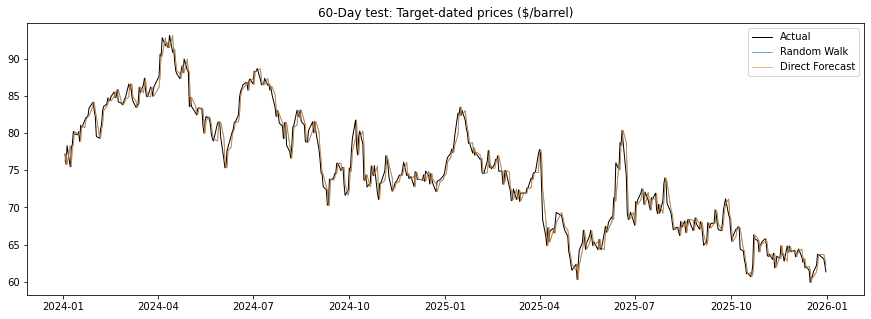

In [20]:
plt.figure(figsize=(15, 5))
plt.plot(np.array(val_results["Random Walk"]["target_date"]), np.array(val_results["Random Walk"]["actual"]), label='Actual', color='black', lw=1)

for name in ["Random Walk", "Direct Forecast"]:
    r = val_results[name]
    plt.plot(np.array(r["target_date"]), np.array(r["forecast"]), label=name, alpha=0.8, lw=0.8)

plt.title("60-Day test: Target-dated prices ($/barrel)")
plt.legend(loc="upper right")
plt.show()

### ==== Test ====

In [15]:
test_args = dict(horizon=60, start_date="2026-01-01", end_date="2026-09-30", target_end_date="2026-09-30")

test_results = {
    "Random Walk": walk_forward(data, forecast_funct=random_walk_forecast, **test_args),
    "Historical Mean": walk_forward(data, forecast_funct=historical_mean_forecast, lookback=3000, **test_args),
    "AR": walk_forward(data, forecast_funct=ar1_forecast, lookback=3000, **test_args),
    "Direct Forecast": walk_forward(data, forecast_funct=direct_forecast, lookback=3000, **test_args),
    "Direct Lag_1 Lag_60": walk_forward(data, forecast_funct=direct_lags_forecast, short=1, long=60, lookback=3000, **test_args),
    "Direct Lag_5 Lag_60": walk_forward(data, forecast_funct=direct_lags_forecast, short=5, long=60, lookback=3000, **test_args),
    "Mean Revert": walk_forward(df_mr, forecast_funct=spread_mr_forecast, lookback=3000, **test_args),
    "XGBoost": walk_forward(data, forecast_funct=xgb_direct_forecast, lookback=3000, **test_args),
    "Direct Ridge": walk_forward(df_rr, forecast_funct=direct_ridge_forecast, lookback=3000, **test_args),
    "Combination": walk_forward(data, forecast_funct=combination_forecast, weights=weights, **test_args)
}

compare_models(test_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,num_trades
model,,,,,,,,,,,,,,
Random Walk,32.663333,37.088322,32.955882,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.0
Historical Mean,32.970212,37.448324,33.241586,0.178295,0.000000,0.000000,0.000000,0.244681,0.396552,0.302632,-2.766387,-4.735027,-0.771169,5.0
AR,32.969282,37.443084,33.240413,0.170543,0.000000,0.000000,0.000000,0.236559,0.379310,0.291391,-2.766387,-4.735027,-0.771169,5.0
Direct Forecast,26.784257,32.426083,25.841311,0.635659,1.000000,0.338028,0.505263,0.552381,1.000000,0.711656,2.764987,4.730877,0.000000,5.0
Direct Lag_1 Lag_60,26.469949,32.113053,25.588352,0.627907,1.000000,0.323944,0.489362,0.547170,1.000000,0.707317,2.764987,4.730877,0.000000,5.0
Direct Lag_5 Lag_60,26.456992,32.120494,25.550504,0.612403,0.920000,0.323944,0.479167,0.538462,0.965517,0.691358,2.764987,4.730877,0.000000,5.0
Mean Revert,30.728036,35.471597,30.230755,0.472868,0.533333,0.338028,0.413793,0.440476,0.637931,0.521127,0.077755,0.044370,0.000000,3.0
XGBoost,37.767243,42.116770,39.954089,0.480620,0.516667,0.873239,0.649215,0.000000,0.000000,0.000000,-1.022467,-0.622183,-0.393137,3.0
Direct Ridge,32.530561,37.042527,32.801530,0.612403,0.723404,0.478873,0.576271,0.548780,0.775862,0.642857,1.021627,0.621770,-0.622729,3.0


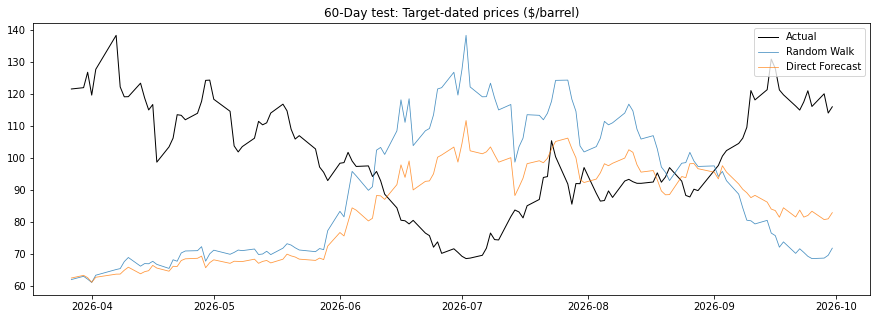

In [21]:
plt.figure(figsize=(15, 5))
plt.plot(np.array(test_results["Random Walk"]["target_date"]), np.array(test_results["Random Walk"]["actual"]), label='Actual', color='black', lw=1)

for name in ["Random Walk", "Direct Forecast"]:
    r = test_results[name]
    plt.plot(np.array(r["target_date"]), np.array(r["forecast"]), label=name, alpha=0.8, lw=0.8)

plt.title("60-Day test: Target-dated prices ($/barrel)")
plt.legend(loc="upper right")
plt.show()

### ==== Final 60-day forecast =====
origin = 2026-09-30

In [17]:
ORIGIN_DATE = "2026-09-30"
HORIZON, LOOKBACK = 60, 3000        # 60 trading days ahead, 3000-day fitting window
SHORT, LONG = 1, 60                 # r_1d and lagged r_60d (non-overlapping, days t-59..t-1)

# 1) Locate the origin (last available trading day on or before ORIGIN_DATE)
dates = data.index
origin_idx = dates.searchsorted(pd.Timestamp(ORIGIN_DATE), side="right") - 1
origin_date = dates[origin_idx]
if origin_date != pd.Timestamp(ORIGIN_DATE):
    print(f"WARNING: {ORIGIN_DATE} not in data, using {origin_date.date()} instead")
fit_idx = origin_idx                # model fitted only on targets known by the origin
start = fit_idx - LOOKBACK + 1
assert start >= 0, "not enough history"

# 2) Rebuild the training set exactly as direct_lags_forecast does (so we can inspect the fit)
lp = np.log(data["brent_spot"].to_numpy(float))        # log of PRICE (not of log_return)

def make_X(t):
    return pd.DataFrame({
        "r_1d":         lp[t] - lp[t - SHORT],         # latest 1-day log return
        "r_60d_lagged": lp[t - SHORT] - lp[t - LONG],  # log return over t-59..t-1
    })

t = np.arange(start + LONG, fit_idx - HORIZON + 1)     # last target = fit_idx
X = make_X(t)
y = pd.Series(lp[t + HORIZON] - lp[t], name="ret_60d_ahead")

fit = sm.OLS(y.values, sm.add_constant(X)).fit(cov_type="HAC", cov_kwds={"maxlags": HORIZON})

# 3) Parameters and significance (Newey-West/HAC, because 60-day targets overlap)
print(fit.summary())
ci = np.asarray(fit.conf_int())
names = fit.model.exog_names
params = pd.DataFrame({"coef": np.asarray(fit.params), "HAC se": np.asarray(fit.bse),
                       "t": np.asarray(fit.tvalues), "p-value": np.asarray(fit.pvalues),
                       "95% low": ci[:, 0], "95% high": ci[:, 1]}, index=names)
print("\n", params.round(4))
print(f"\nobs = {len(y)}  (~{len(y)//HORIZON} non-overlapping 60-day windows)")
print(f"R2 = {fit.rsquared:.4f}   joint Wald p-value = {fit.f_pvalue:.4f}")

# 4) Forecast from the origin
x0 = np.r_[1.0, make_X(np.array([origin_idx])).to_numpy()[0]]
beta = np.asarray(fit.params)
pred_ret = float(x0 @ beta)
se_mean = float(np.sqrt(x0 @ np.asarray(fit.cov_params()) @ x0))   # uncertainty of expected return
sigma = float(np.sqrt(fit.scale))                       # residual sd of a 60-day return
sd_total = np.sqrt(se_mean**2 + sigma**2)
p0 = data["brent_spot"].iloc[origin_idx]
f = lambda r: p0 * np.exp(r)

# sanity check against the function used in the backtest
fc_fn = direct_lags_forecast(data, origin_idx, horizon=HORIZON, fit_idx=fit_idx,
                             lookback=LOOKBACK, short=SHORT, long=LONG,
                             nonoverlap=True, use_intercept=True)
assert np.isclose(f(pred_ret), fc_fn), "cell and model function disagree"

target_date = pd.bdate_range(origin_date, periods=HORIZON + 1)[-1]   # approx: ignores holidays
print(f"\nOrigin {origin_date.date()}  price = {p0:.2f}")
print(f"Features: r_1d = {x0[1]:+.4f}, r_60d_lagged = {x0[2]:+.4f}")
print(f"Predicted 60-day log return = {pred_ret:+.4f}  (expected-return 95% CI "
      f"{pred_ret-1.96*se_mean:+.4f} to {pred_ret+1.96*se_mean:+.4f})")
print(f"Point forecast for ~{target_date.date()}: {f(pred_ret):.2f}")
print(f"95% prediction interval: {f(pred_ret-1.96*sd_total):.2f} to {f(pred_ret+1.96*sd_total):.2f}")
print(f"Random-walk forecast: {p0:.2f}")

# 5) Optional: how the forecast is doing so far, if data already runs past the origin
elapsed = len(data) - 1 - origin_idx
if elapsed > 0:
    print(f"\n{elapsed} trading days elapsed. Latest {data.index[-1].date()}: "
          f"{data['brent_spot'].iloc[-1]:.2f} (realised log return {lp[-1]-lp[origin_idx]:+.4f})")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.121
Model:                            OLS   Adj. R-squared:                  0.120
Method:                 Least Squares   F-statistic:                     7.035
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           0.000896
Time:                        01:57:00   Log-Likelihood:                 166.33
No. Observations:                2880   AIC:                            -326.7
Df Residuals:                    2877   BIC:                            -308.8
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0144      0.027      0.533   

#### GARCH-based prediction interval

In [18]:
from arch import arch_model

def garch_interval_forecast(df, origin_idx, horizon=60, fit_idx=None, lookback=3000,
                            center_fn=None, level=0.95, vol="garch", gjr=False):
    """Prediction interval for Brent at origin+horizon.
    - centre : log-return forecast of `center_fn` (default: random walk, 0 return)
    - width  : sqrt of the summed h-step GARCH(1,1)-t variance forecasts
               (vol="constant" gives the benchmark sd*sqrt(h) from the fit window)
    - params are estimated on data up to fit_idx only; the volatility state is then
      filtered up to origin_idx with params frozen (no look-ahead).
    Returns dict(forecast, lower, upper, sigma_h)."""
    fit_idx = origin_idx if fit_idx is None else fit_idx
    assert fit_idx <= origin_idx, "fit_idx must not be after origin_idx (lookahead)"
    start = fit_idx - lookback + 1
    assert start >= 0, "not enough history for the lookback window"

    r = df["log_return"].to_numpy(float)
    assert not np.isnan(r[start: origin_idx + 1]).any(), "NaNs in return window"
    p_t = df["brent_spot"].iloc[origin_idx]

    used = vol
    if vol == "garch":
        spec = dict(mean="Zero", vol="GARCH", p=1, o=int(gjr), q=1, dist="t", rescale=False)
        fit = arch_model(r[start: fit_idx + 1] * 100, **spec).fit(disp="off")   # pct scale
        if fit.convergence_flag != 0:
            used = "constant (garch failed)"
        else:
            filt = arch_model(r[start: origin_idx + 1] * 100, **spec).fix(fit.params)
            var_path = filt.forecast(horizon=horizon, reindex=False).variance.to_numpy()[-1]
            sigma_h = np.sqrt(var_path.sum()) / 100          # sd of the h-day cumulative log return
    if used != "garch":
        sigma_h = r[start: fit_idx + 1].std(ddof=1) * np.sqrt(horizon)

    pred_ret = 0.0 if center_fn is None else np.log(center_fn(df, origin_idx, horizon, fit_idx) / p_t)
    z = stats.norm.ppf(0.5 + level / 2)    # 60-day sum of returns is close to normal even if daily is fat-tailed
    return {"forecast": p_t * np.exp(pred_ret),
            "lower": p_t * np.exp(pred_ret - z * sigma_h),
            "upper": p_t * np.exp(pred_ret + z * sigma_h),
            "sigma_h": sigma_h, "vol_used": used}


In [19]:
from functools import partial

origin_idx = data.index.searchsorted(pd.Timestamp("2026-09-30"), side="right") - 1
point_model = partial(direct_lags_forecast, short=1, long=60, lookback=3000)

garch_interval_forecast(data, origin_idx, horizon=60, fit_idx=origin_idx,
                              lookback=3000, center_fn=point_model, level=0.95)

{'forecast': 99.44237634709832,
 'lower': 62.53797929642956,
 'upper': 158.1244921055918,
 'sigma_h': 0.23663919691476404,
 'vol_used': 'garch'}